# 일기 저장 MCP 서버


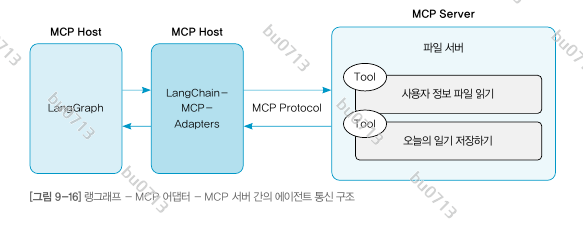

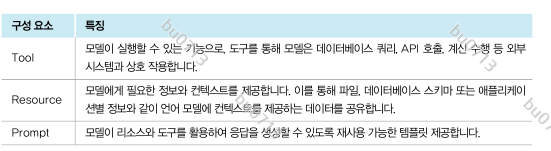

# 세팅

In [1]:
! uv pip install langchain-mcp-adapters

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 1.60s


In [2]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("OPENAI API Key가 설정되었습니다.")

OPENAI API Key가 설정되었습니다.


# MCP 서버 구성

In [ ]:
from mcp.server.fastmcp import FastMCP                # FastMCP 서버 클래스를 가져옴
from mcp.server.fastmcp.prompts import base           # 프롬프트 메시지 타입(AssistantMessage, UserMessage)을 가져옴
from datetime import datetime                         # 현재 날짜/시간을 다루기 위한 모듈
from pathlib import Path                              # 경로 조작을 위한 Path 클래스


mcp = FastMCP("MCPServer") # [ 1 ]                    # "MCPServer"라는 이름으로 FastMCP 서버 인스턴스를 생성


@mcp.tool() # [ 2 ]                                   # 아래 함수를 MCP 도구(tool)로 등록하는 데코레이터
def read_user_info() -> str:
    """
    사용자의 정보를 담고 있는 txt 파일을 읽어옵니다.

    Returns:
        str: my_info.txt 파일의 내용
    """
    # 현재 파이썬 파일이 위치한 디렉터리 경로에 "my_info.txt" 파일명을 결합하여 전체 경로를 생성
    info_file_path = Path(__file__).parent / "my_info.txt" # [ 3 ]

    try:
        # 파일을 UTF-8 인코딩, 읽기 모드로 열기
        with open(info_file_path, "r", encoding="utf-8") as f:
            content = f.read()                        # 파일 전체 내용을 문자열로 읽음
        return content                                # 읽은 내용을 반환
    except FileNotFoundError:
        # 파일이 존재하지 않을 때 처리
        return "my_info.txt 파일을 찾을 수 없습니다."
    except Exception as e:
        # 그 외 모든 예외 발생 시 오류 메시지를 문자열로 반환
        return f"파일을 읽는 중 오류가 발생했습니다: {str(e)}"

@mcp.tool()                                           # save_diary 함수를 MCP 도구로 등록
def save_diary(conversation_summary: str, emotion: str, resolution: str) -> dict:
    """
    일기 형태로 텍스트 파일을 저장합니다. 모든 내용은 한국어로 작성합니다.

    Args:
        conversation_summary (str): 오늘의 대화 내용
        emotion (str): 오늘의 감정
        resolution (str): 오늘의 다짐

    Returns:
        dict: 저장 결과 (저장 경로, 파일명, 성공 여부)
    """ # [ 1 ]                                       # docstring은 LLM이 도구의 용도와 인자를 이해하는 설명으로 사용됨
    try:
        # 현재 파일이 위치한 디렉터리 아래에 "diary" 폴더 경로를 생성
        diary_dir = Path(__file__).parent / "diary" # [ 2 ]
        diary_dir.mkdir(exist_ok=True)                # diary 폴더가 없으면 생성, 이미 있으면 그대로 사용

        # 파일명은 날짜_시간으로 자동 생성
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S") # [ 3 ]  # 현재 시각을 "20260720_153045" 형태의 문자열로 변환
        filename = f"diary_{timestamp}.txt"           # "diary_날짜_시간.txt" 형태의 파일명 생성
        file_path = diary_dir / filename              # diary 폴더 경로와 파일명을 결합하여 최종 저장 경로 생성

        # 날짜와 시간 정보
        timestamp_str = datetime.now().strftime("%Y년 %m월 %d일 %H시 %M분") # [ 4 ]  # 일기 본문에 표시할 한국어 형식의 날짜/시간 문자열

        # 일기 형식으로 내용 구성 (f-string으로 전달받은 인자들을 일기 템플릿에 삽입)
        full_content = f"""[{timestamp_str}]

📝 오늘의 대화 내용
{conversation_summary}

💭 오늘의 감정
{emotion}

✨ 오늘의 다짐
{resolution}
"""

        # 파일 저장
        with open(file_path, "w", encoding="utf-8") as f: # [ 5 ]  # 파일을 UTF-8 인코딩, 쓰기 모드로 열기
            f.write(full_content)                     # 구성한 일기 내용을 파일에 기록

        # 저장 성공 시 결과 정보를 딕셔너리로 반환
        return {
            "success": True,                          # 저장 성공 여부
            "path": str(file_path.absolute()),        # 저장된 파일의 절대 경로
            "filename": filename,                     # 저장된 파일명
            "message": f"일기가 성공적으로 저장되었습니다."  # 성공 메시지
        }
    except Exception as e:
        # 저장 과정에서 예외 발생 시 실패 정보를 딕셔너리로 반환
        return {
            "success": False,                         # 저장 실패 여부
            "message": f"파일 저장 중 오류가 발생했습니다: {str(e)}"  # 오류 메시지
        }

@mcp.prompt()                                         # 아래 함수를 MCP 프롬프트로 등록하는 데코레이터
def default_prompt(message: str) -> list[base.Message]:
    # 프롬프트 호출 시 반환할 메시지 리스트를 구성
    return [
        # 어시스턴트 역할 메시지: LLM의 페르소나와 행동 지침을 정의
        base.AssistantMessage(
            "당신은 따뜻하고 공감 능력이 뛰어난 개인 비서입니다. \n"
            "- 사용자가 오늘 있었던 일을 편하게 이야기할 수 있도록 경청하고 공감해주세요\n"
            "- 대화가 자연스럽게 이어지도록 적절한 질문을 던져주세요\n"
            "- 사용자의 감정을 이해하고 긍정적인 피드백을 제공해주세요\n"
            "- 사용자가 대화를 끝내려 하면, 지금까지의 대화 내용을 담아 일기를 작성하세요\n"
            "- 존댓말을 사용하되, 친근하고 편안한 말투를 사용하세요"
        ),
        # 사용자 역할 메시지: 인자로 전달받은 message를 사용자 메시지로 추가
        base.UserMessage(message),
    ]

if __name__ == "__main__":                            # 이 파일이 직접 실행될 때만 아래 코드를 실행
    print("MCP server started and waiting for clients...")  # 서버 시작 안내 메시지 출력
    mcp.run(transport="streamable-http")              # streamable-http 전송 방식으로 MCP 서버 실행 (기본 포트 8000)

서버 커기

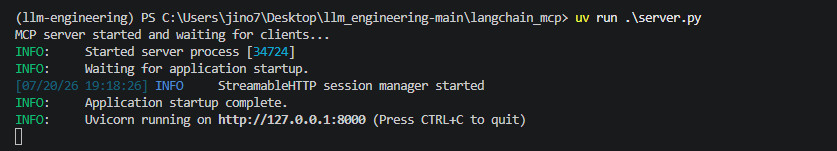

# MCP 클라이언트 구성

In [3]:
# ============================================
# [셀 1] 임포트 및 기본 설정
# ============================================
import gradio as gr
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_mcp_adapters.prompts import load_mcp_prompt
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv


# 사용할 LLM 모델 정의
model = ChatOpenAI(model="gpt-5-mini")

# "diary" MCP 서버에 streamable_http 전송 방식으로 연결하는 클라이언트를 생성
# 서버(server.py)는 포트 8000에서 mcp.run(transport="streamable-http")로 실행 중이어야 함
client = MultiServerMCPClient(
    {
        "diary": {
            "url": "http://localhost:8000/mcp",
            "transport": "streamable_http",
        },
    }
)

# 대화 기록을 저장하는 체크포인터
# 매 요청마다 에이전트를 새로 만들더라도, 같은 thread_id로 조회하면
# 이전 대화 내용이 그대로 이어짐
checkpointer = InMemorySaver()

In [4]:
# ============================================
# [셀 2] Gradio에서 호출할 비동기 응답 함수
# ============================================
async def respond(message, history):
    """
    Gradio ChatInterface가 호출하는 응답 함수.
    message: 사용자가 방금 입력한 텍스트
    history: 지금까지의 화면상 대화 기록 (list)
    """
    # MCP 서버의 tool들을 LangChain tool 형태로 변환
    # (get_tools는 호출 시마다 내부적으로 새 세션을 열어 tool 목록을 가져옴)
    tools = await client.get_tools()

    # 전역 체크포인터를 연결하여 에이전트 생성
    agent = create_agent(model, tools, checkpointer=checkpointer)

    # 첫 번째 입력이면 MCP 서버에 정의된 default_prompt를 불러와서 사용
    if len(history) == 0:
        # "diary" 서버에 새 세션을 열고 프롬프트를 로드
        async with client.session("diary") as session:
            prompts = await load_mcp_prompt(
                session, "default_prompt", arguments={"message": message}
            )
    # 이후 입력은 사용자 메시지만 전달 (이전 대화는 checkpointer가 복원)
    else:
        prompts = [{"role": "user", "content": message}]

    # 에이전트 실행
    response = await agent.ainvoke(
        {"messages": prompts},
        config={"configurable": {"user_id": "user_123", "thread_id": "1"}},
    )

    # 마지막 메시지(최종 AI 응답)의 내용을 반환
    return response["messages"][-1].content

안녕 오늘 하루도 무사해 끝났네!

오늘 첫 출근인데 약간 피곤햇어

그런건 없어 수고했어 내일 봐

In [5]:
# ============================================
# [셀 3] Gradio UI 실행
# ============================================
demo = gr.ChatInterface(
    fn=respond,                # 비동기 함수도 그대로 전달 가능
    type="messages",           # OpenAI 스타일 messages 형식 사용
    title="MCP 일기 비서",
    description="오늘 있었던 일을 편하게 이야기해 보세요. 대화를 마치면 일기로 저장해 드립니다.",
)

# 주피터 노트북에서는 launch() 호출 시 셀 출력 영역에 UI가 인라인으로 표시됨
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


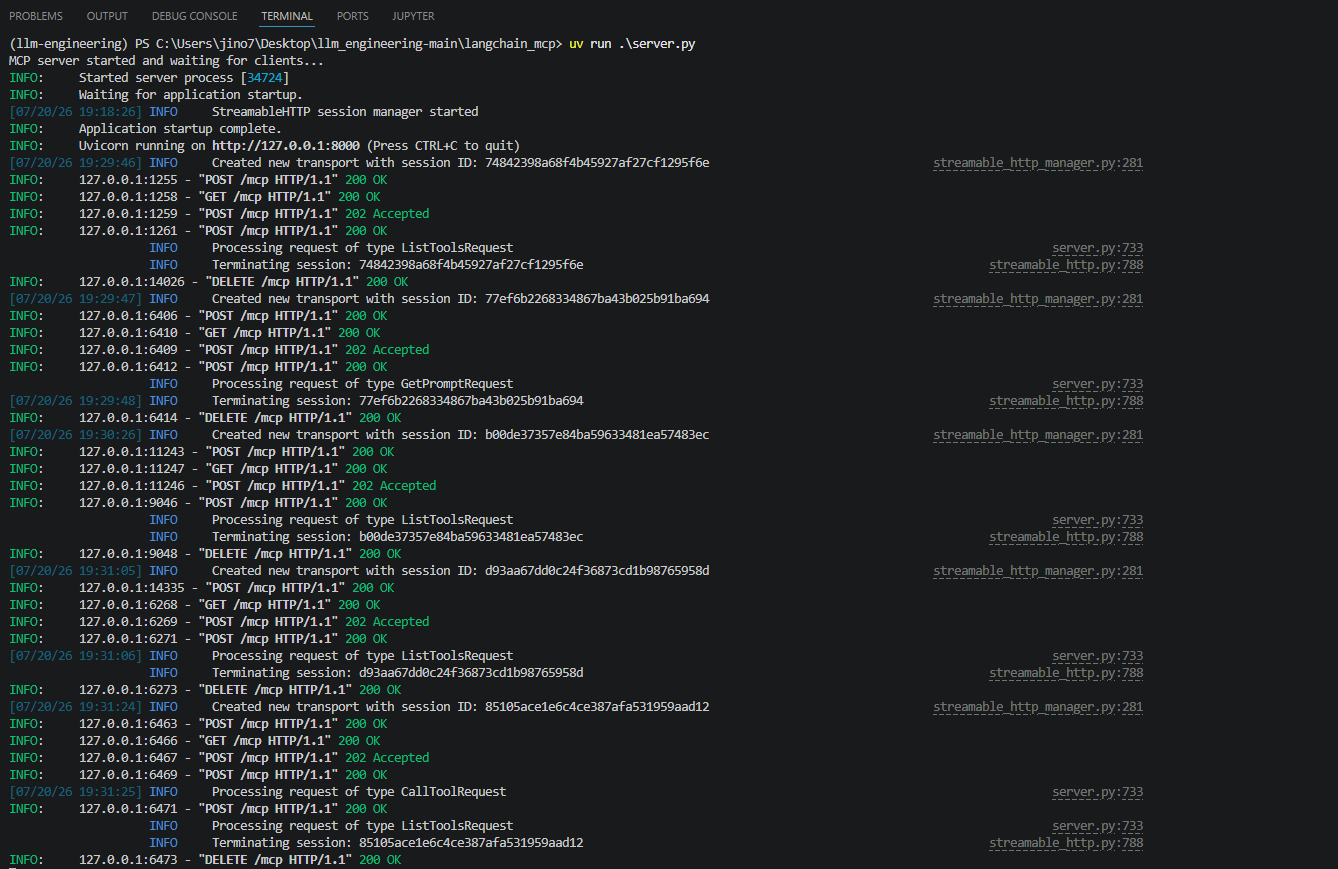